# New pattern detectors: cup and handle + smart money concepts

Built on the `ophand` branch after a web search for the patterns traders talk about most. Two families were missing from the repo:

| Family | Detectors |
|---|---|
| **Cup and handle** | rounded bottom between two similar rims, a small handle pullback, signalled when price closes above the right rim |
| **Smart money concepts (SMC)** | **break of structure (BOS)**, **change of character (CHoCH)**, **liquidity sweeps**, **fair value gaps (FVG)**, **order blocks (OB)**, with signals both at formation and at the first retest of a gap/block |

This notebook does two things:
1. **Checks that the detectors are accurate** (section 1).
2. **Tests whether the patterns predict anything** on ETH, SOL, BNB, XRP, ADA and DOGE at daily, 4-hour and hourly bars, with data through 14 Oct 2026 (sections 2-5).

Every detector reports a pattern on the bar where it is first *known*. Definitions and thresholds were fixed from the textbook descriptions before any returns were looked at.

In [1]:
import subprocess, sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, 'tests')

from new_patterns import (COINS, HORIZONS, prepare_new, load_tf, add_momentum_controls)
from smart_money import plot_smc, ORDER
from cup_handle import find_cup_handles, plot_cup_handle, PARAMS as CUP_PARAMS
from cross_coin import pooled_evaluate, summarize_pooled, benjamini_hochberg
from strategy_lab import add_features, evaluate, judge, GRID_DAILY, GRID_4H

TEST_START = '2024-01-01'
BLUE, ORANGE, AQUA, YELLOW, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#c98500', '#8a8984'
plt.rcParams.update({
    'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.spines.top': False,
    'axes.spines.right': False, 'lines.linewidth': 1.6, 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
})
pd.set_option('display.width', 250); pd.set_option('display.max_rows', 100); pd.set_option('display.max_colwidth', 38)

## 1. Are the detectors accurate?

**Definitions used**

| Pattern | Rule |
|---|---|
| Swing high / low | highest high / lowest low within `order` bars each side (daily 4, 4h 5, hourly 6), known `order` bars later |
| BOS | a *close* beyond the latest unbroken swing level, in the direction of the current trend |
| CHoCH | a close beyond the latest swing level *against* the current trend |
| Liquidity sweep | a wick beyond a recent unswept swing level that **closes back inside** (a close beyond it is a breakdown, not a sweep) |
| Fair value gap | 3-candle gap: bullish if low[i] > high[i-2] (bearish mirror), gap ≥ 0.25 ATR |
| Order block | last opposing candle (within 6 bars) before a displacement candle (body ≥ 1.5 ATR) that also breaks structure |
| Retest | first bar within 30 bars of formation that trades back into the zone and closes without breaking through it |
| Cup and handle | rims are swing highs within 7% of each other; cup 30-150 bars wide and 10-36% deep; U-shaped (parabola R² ≥ 0.7, bottom in the middle 40%, ≥60% of bars in the lower half); handle ≥ 5 bars retracing ≤ half the cup; signal = first close above the right rim |

### 1a. Automated tests
24 tests in `tests/test_detectors.py`: hand-built candles with known answers for every SMC definition (including near-misses that must **not** fire), planted and malformed cups, a random-walk false-positive limit, and a **no-lookahead test** that re-runs every detector on truncated data and requires identical events.

In [2]:
r = subprocess.run([sys.executable, '-m', 'pytest', 'tests', '-v', '-p', 'no:cacheprovider'], capture_output=True, text=True)
lines = [l for l in r.stdout.splitlines() if '::' in l]
for l in lines:
    print(('PASS  ' if 'PASSED' in l else 'FAIL  ') + l.split('::')[1].split(' ')[0])
print('\n' + r.stdout.strip().splitlines()[-1])

PASS  test_bullish_fvg_zone_and_retest
PASS  test_no_fvg_when_candles_overlap
PASS  test_fvg_invalidated_by_close_below_zone
PASS  test_bearish_fvg
PASS  test_tiny_gap_is_ignored
PASS  test_bos_then_choch
PASS  test_structure_break_needs_a_close_not_a_wick
PASS  test_bullish_sweep_wick_below_close_above
PASS  test_breakdown_is_not_a_sweep
PASS  test_sweep_fires_once_per_level
PASS  test_bullish_order_block_is_last_down_candle_before_impulse
PASS  test_small_candle_break_is_not_an_order_block
PASS  test_smc_events_do_not_use_future_bars[random]
PASS  test_smc_events_do_not_use_future_bars[real]
PASS  test_cup_handle_does_not_use_future_bars[random]
PASS  test_cup_handle_does_not_use_future_bars[real]
PASS  test_detects_planted_cup_and_handle
PASS  test_rejects_malformed_cups[kwargs0-V-shaped
PASS  test_rejects_malformed_cups[kwargs1-handle
PASS  test_rejects_malformed_cups[kwargs2-cup
PASS  test_rejects_malformed_cups[kwargs3-cup
PASS  test_rejects_malformed_cups[kwargs4-right
PASS  tes

### 1b. Planted cup and handle, and malformed shapes
A synthetic cup (parabola, 60 bars, 25% deep, 8-bar handle, small noise) is hidden in the data. The detector must find it at the right place, and must **reject** each broken variant.

planted: left rim bar 30, right rim bar 90   |   found: left 29, right 90, breakout 102, drop 22%, R2 1.00
valid cup and handle            1
V-shaped bottom                 0
handle > half the cup           0
cup too narrow (18 bars)        0
cup too shallow (4%)            0
right rim far below left rim    0
handle too short (2 bars)       0


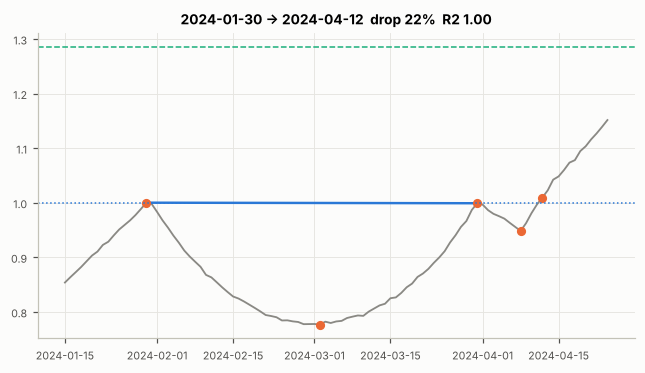

In [3]:
from test_detectors import _cup_path
path, left, right = _cup_path()
close = np.exp(path)
ohlc = pd.DataFrame({'open': np.r_[close[0], close[:-1]], 'close': close})
ohlc['high'] = ohlc[['open', 'close']].max(axis=1) * 1.002; ohlc['low'] = ohlc[['open', 'close']].min(axis=1) * 0.998
ohlc.index = pd.date_range('2024-01-01', periods=len(ohlc), freq='D')
p = find_cup_handles(path, order=5)[0]
print(f'planted: left rim bar {left}, right rim bar {right}   |   found: left {p.left_i}, right {p.right_i}, breakout {p.break_i}, drop {100 * (1 - np.exp(-p.depth)):.0f}%, R2 {p.r2:.2f}')

cases = {'valid cup and handle': {}, 'V-shaped bottom': dict(v_shape=True), 'handle > half the cup': dict(handle_depth=0.17),
         'cup too narrow (18 bars)': dict(width=18), 'cup too shallow (4%)': dict(depth=0.04),
         'right rim far below left rim': dict(right_rim=-0.12), 'handle too short (2 bars)': dict(handle_bars=2, handle_depth=0.03)}
print(pd.Series({k: len(find_cup_handles(_cup_path(**v)[0], order=5)) for k, v in cases.items()}, name='cups found').to_string())
fig, ax = plt.subplots(figsize=(7, 3.6)); plot_cup_handle(ohlc, p, ax); plt.show()

### 1c. Do cups appear more often in real prices than in shuffled prices?
If a detector fires just as often on data where the order of daily returns has been shuffled (so no real structure remains), it is mostly detecting noise. Cups per 1,000 bars, real vs. 100 shuffles of each coin's own returns.

In [4]:
rng = np.random.default_rng(0)
rows = []
for tf in ('daily', '4h'):
    for s in COINS:
        c = np.log(load_tf(s, tf)['close'].to_numpy()); r = np.diff(c)
        real = len(find_cup_handles(c, **CUP_PARAMS[tf])) / len(c) * 1000
        sh = [len(find_cup_handles(np.r_[c[0], c[0] + np.cumsum(rng.permutation(r))], **CUP_PARAMS[tf])) / len(c) * 1000 for _ in range(100)]
        rows.append(dict(tf=tf, coin=s[:-4], bars=len(c), real_per_1000=real, shuffled_mean=np.mean(sh), shuffled_95th=np.percentile(sh, 95)))
null = pd.DataFrame(rows)
tot = null.groupby('tf').apply(lambda g: pd.Series({'real_per_1000': np.average(g['real_per_1000'], weights=g['bars']),
                                                    'shuffled_mean': np.average(g['shuffled_mean'], weights=g['bars'])}))
display(null.round(2)); print('All coins, bar-weighted:'); display(tot.round(2))

,tf,coin,bars,real_per_1000,shuffled_mean,shuffled_95th
0,daily,ETH,3208,0.31,0.21,0.64
1,daily,SOL,2255,0.89,0.07,0.44
2,daily,BNB,3208,0.31,0.27,0.94
3,daily,XRP,3085,0.32,0.18,0.65
4,daily,ADA,3102,0.32,0.11,0.32
5,daily,DOGE,2658,0.38,0.13,0.38
6,4h,ETH,19238,0.16,0.18,0.36
7,4h,SOL,13535,0.22,0.07,0.15
8,4h,BNB,19238,0.05,0.18,0.31
9,4h,XRP,18505,0.16,0.13,0.27


All coins, bar-weighted:


,real_per_1000,shuffled_mean
tf,,
4h,0.16,0.14
daily,0.40,0.17


### 1d. Visual check: do the detections look like the textbook patterns?
Annotated real charts. **Boxes** = fair value gaps (blue bullish, orange bearish) and order blocks (dark green/red), drawn from formation until retested or broken. **Triangles** = liquidity sweeps. **Dashed lines** = broken swing levels, labelled BOS / CHoCH (+ up, − down).

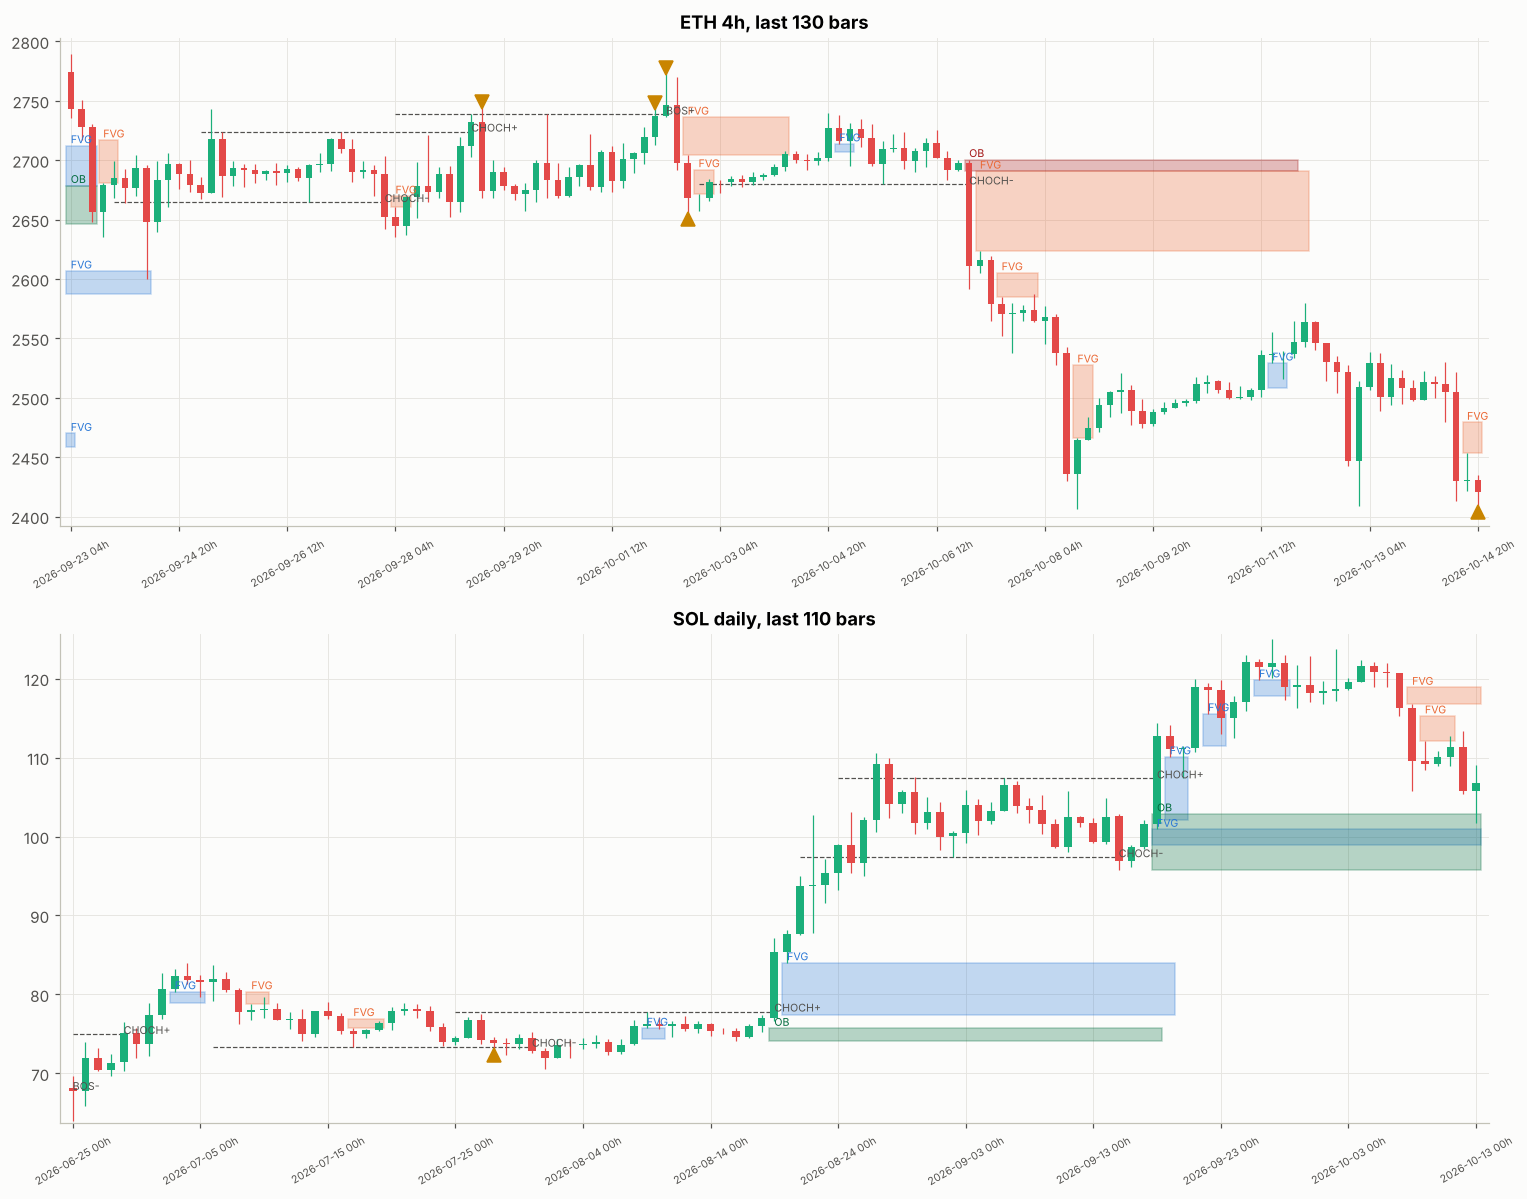

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(14, 11))
o = load_tf('ETHUSDT', '4h'); e = len(o) - 1
plot_smc(o, e - 130, e, ORDER['4h'], ax=axs[0]); axs[0].set_title('ETH 4h, last 130 bars')
o = load_tf('SOLUSDT', 'daily'); e = len(o) - 1
plot_smc(o, e - 110, e, ORDER['daily'], ax=axs[1]); axs[1].set_title('SOL daily, last 110 bars')
plt.tight_layout(); plt.show()

24 cup-and-handle detections on daily and 4-hour bars of the 6 coins (up to 12 shown)


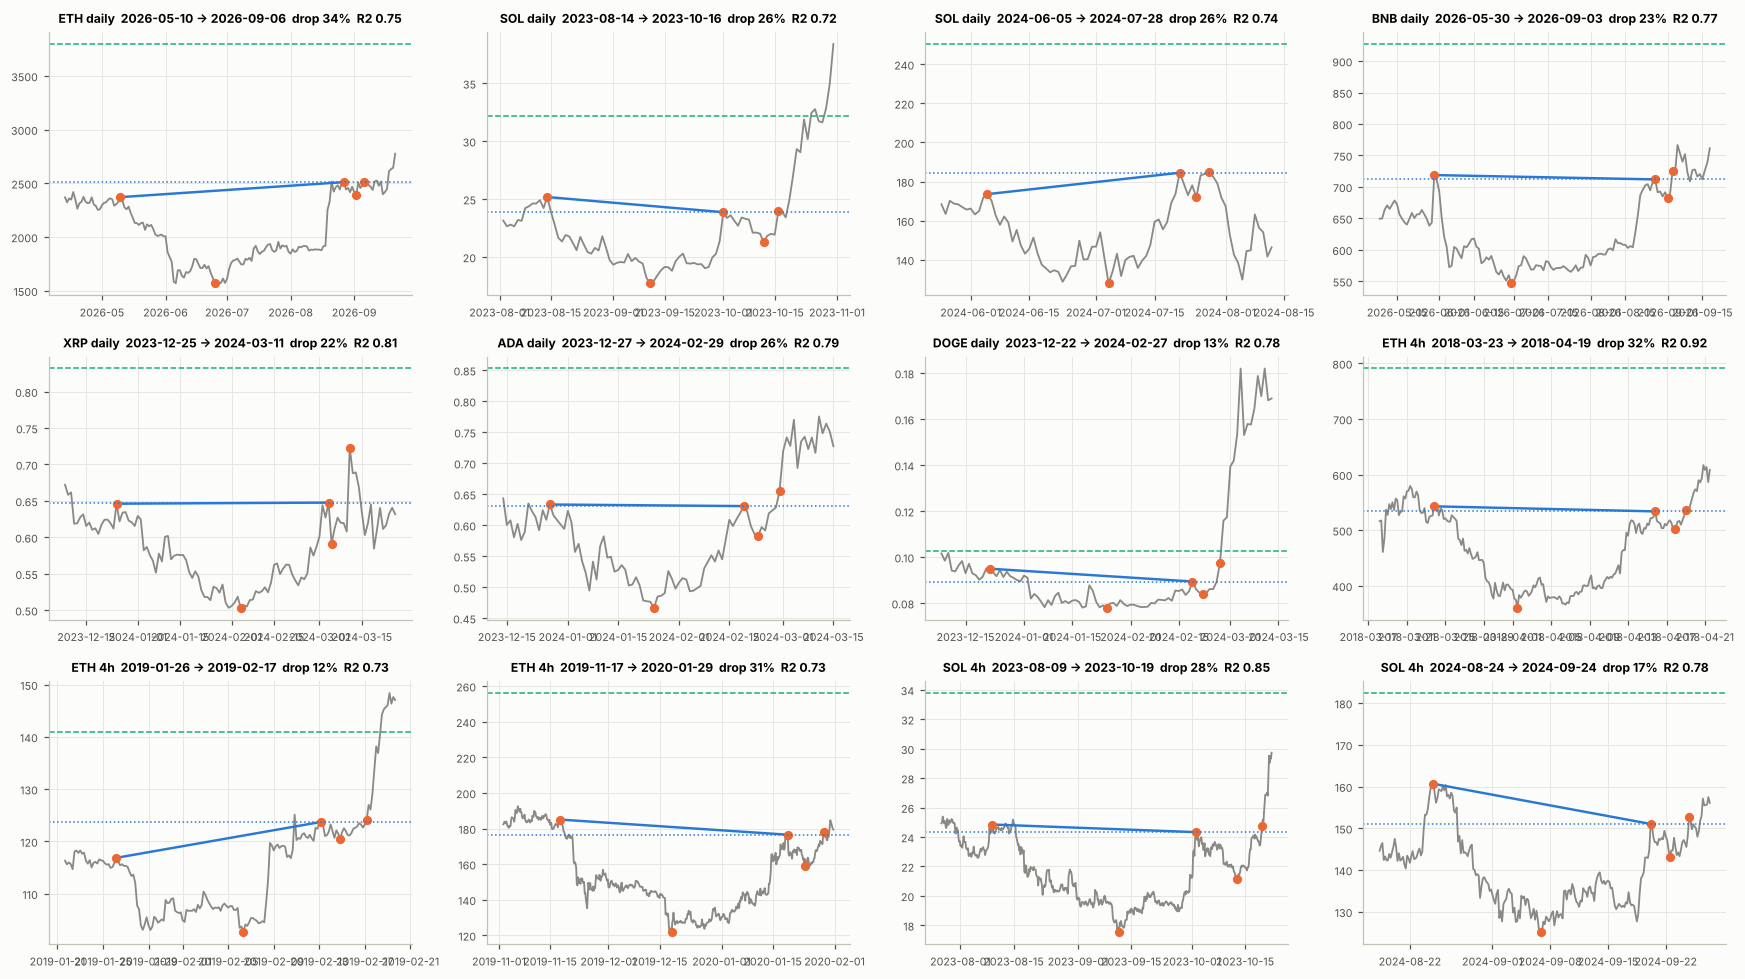

In [6]:
dets = []
for tf in ('daily', '4h'):
    for s in COINS:
        o = load_tf(s, tf)
        dets += [(tf, s, o, p) for p in find_cup_handles(np.log(o['close'].to_numpy()), **CUP_PARAMS[tf])]
print(f'{len(dets)} cup-and-handle detections on daily and 4-hour bars of the 6 coins (up to 12 shown)')
fig, axs = plt.subplots(3, 4, figsize=(16, 9))
for ax, (tf, s, o, p) in zip(axs.flat, dets[:12]):
    plot_cup_handle(o, p, ax); ax.set_title(f'{s[:-4]} {tf}  ' + ax.get_title(), fontsize=8)
for ax in list(axs.flat)[len(dets[:12]):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

**What was and was not verified.** The tests prove each detector does what its written definition says, never uses future bars, and rejects near-misses. They cannot prove that the definition matches every trader's idea of the pattern: SMC terms in particular are used loosely, and other people's order-block or CHoCH rules differ in details.

## 2. Do the patterns predict returns? (pooled over six coins)

For each pattern: the forward return in its direction minus the return from entering on random bars (same coin, same period). **Earlier** = before 2024, **recent** = 2024 onward. The p-value is from a permutation test, and the **q-value corrects it for the number of patterns tested across all timeframes**.
Horizons: daily 5 bars, 4h 18 bars (3 days), hourly 24 bars.

In [7]:
H = {'daily': 5, '4h': 18, 'hourly': 24}
data, res_all, sums = {}, {}, []
for tf in ('daily', '4h', 'hourly'):
    data[tf] = prepare_new(COINS, tf, TEST_START)
    res_all[tf] = pooled_evaluate(data[tf], HORIZONS[tf], n_perm=500)
    s = summarize_pooled(res_all[tf], H[tf], min_n=30).reset_index(); s['tf'] = tf; sums.append(s)
summ = pd.concat(sums, ignore_index=True)
ok = (summ['is_n'] >= 30) & (summ['recent_n'] >= 30)
summ['q_global'] = np.nan
summ.loc[ok, 'q_global'] = benjamini_hochberg(summ.loc[ok, 'recent_p_value'].to_numpy())
summ['verdict'] = np.where(~ok, 'too few', np.where((summ['is_excess_pct'] > 0) & (summ['recent_excess_pct'] > 0) & (summ['q_global'] < 0.1), 'edge holds',
                  np.where((summ['is_excess_pct'] > 0) & (summ['recent_excess_pct'] > 0) & (summ['recent_p_value'] < 0.1), 'promising',
                  np.where((summ['is_excess_pct'] > 0) & (summ['recent_excess_pct'] > 0), 'weak', np.where(summ['is_excess_pct'] > 0, 'faded', 'none')))))
cols = ['tf', 'pattern', 'is_n', 'is_excess_pct', 'is_p_value', 'recent_n', 'recent_n_coins_pos', 'recent_hit_rate', 'recent_excess_pct', 'recent_p_value', 'q_global', 'verdict']
order = {'edge holds': 0, 'promising': 1, 'weak': 2, 'faded': 3, 'none': 4, 'too few': 5}
view = summ.assign(_o=summ['verdict'].map(order)).sort_values(['_o', 'q_global', 'recent_excess_pct'], ascending=[True, True, False])[cols].drop(columns=[], errors='ignore')
print(summ['verdict'].value_counts().to_string()); print()
view.reset_index(drop=True).round(3)

verdict
faded         14
none          11
edge holds     8
promising      4
weak           4
too few        4



,tf,pattern,is_n,is_excess_pct,is_p_value,recent_n,recent_n_coins_pos,recent_hit_rate,recent_excess_pct,recent_p_value,q_global,verdict
0,daily,ob_bull_form,89,3.998,0.004,55,5,0.618,4.639,0.002,0.041,edge holds
1,daily,bos_bull,144,4.000,0.002,71,5,0.606,4.129,0.002,0.041,edge holds
2,daily,ob_bull_retest,41,0.675,0.363,35,6,0.571,4.218,0.006,0.082,edge holds
3,daily,fvg_bear_retest,341,1.223,0.028,213,4,0.596,1.429,0.012,0.082,edge holds
4,4h,bos_bull,821,1.697,0.002,417,5,0.458,0.777,0.014,0.082,edge holds
5,4h,fvg_bull_form,3215,1.246,0.002,1824,5,0.474,0.367,0.014,0.082,edge holds
6,hourly,bos_bull,2746,0.300,0.006,1513,4,0.473,0.240,0.016,0.082,edge holds
7,hourly,fvg_bull_form,12222,0.278,0.002,6973,5,0.480,0.098,0.016,0.082,edge holds
8,hourly,ob_bull_form,1878,0.726,0.002,903,5,0.474,0.262,0.036,0.147,promising
9,hourly,fvg_bear_retest,9110,0.020,0.365,5221,5,0.496,0.112,0.036,0.147,promising


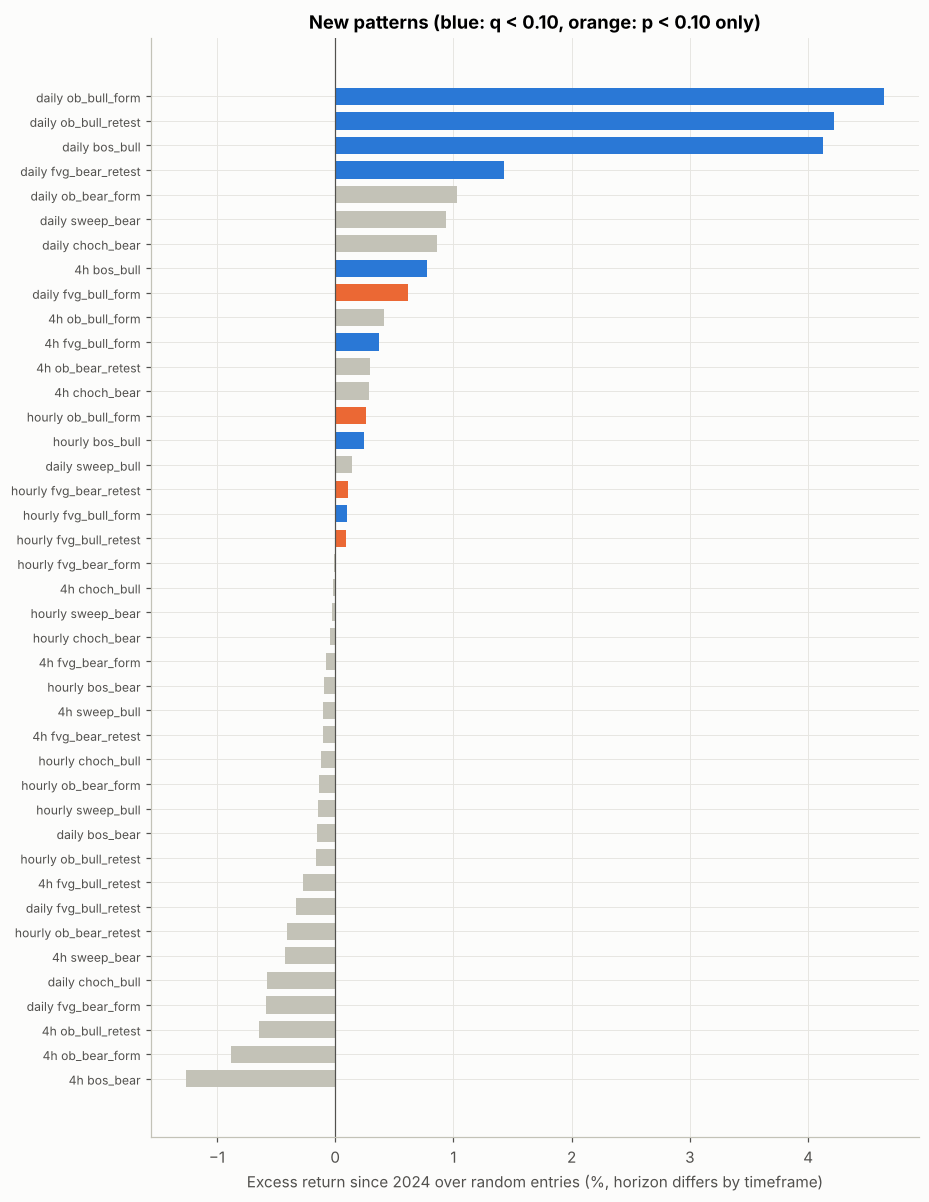

In [8]:
v = summ[summ['verdict'] != 'too few'].copy()
v['label'] = v['tf'] + ' ' + v['pattern']
v = v.sort_values('recent_excess_pct')
col = [BLUE if q < 0.1 else (ORANGE if p < 0.1 else '#c3c2b7') for q, p in zip(v['q_global'], v['recent_p_value'])]
fig, ax = plt.subplots(figsize=(9, 0.28 * len(v) + 1.5))
ax.barh(v['label'], v['recent_excess_pct'], color=col, height=0.7)
ax.axvline(0, color='#52514e', lw=0.8)
ax.set_xlabel('Excess return since 2024 over random entries (%, horizon differs by timeframe)')
ax.set_title('New patterns (blue: q < 0.10, orange: p < 0.10 only)')
plt.tick_params(axis='y', labelsize=8); plt.show()

**A pattern in the pattern:** the *bullish* impulse patterns (break of structure up, bullish order block / FVG formation) do well, and their bearish mirrors do not. That is what a momentum effect looks like, so the next section checks whether these patterns add anything beyond "price just made a new high".

## 3. Is it just momentum?

Control "patterns" with no smart-money logic at all: a close above the previous 20-bar high on daily bars, or the previous 60-bar high on 4-hour bars (`high20` / `high60`), and the mirror lows. If a plain new-high breakout earns the same excess, the SMC pattern adds nothing.

In [9]:
mom = {}
for tf, n in (('daily', 20), ('4h', 60)):
    c = prepare_new(COINS, tf, TEST_START); add_momentum_controls(c, n); mom[tf] = c
    r = pooled_evaluate(c, [H[tf]], n_perm=500)
    s = summarize_pooled(r, H[tf], min_n=30)
    print(f'--- {tf}, {H[tf]} bars ahead ---')
    display(s.loc[[p for p in ['bos_bull', 'ob_bull_form', 'fvg_bull_form', f'high{n}', 'bos_bear', 'fvg_bear_retest', f'low{n}'] if p in s.index],
                  ['is_n', 'is_excess_pct', 'is_p_value', 'recent_n', 'recent_excess_pct', 'recent_p_value']].round(3))

--- daily, 5 bars ahead ---


,is_n,is_excess_pct,is_p_value,recent_n,recent_excess_pct,recent_p_value
pattern,,,,,,
bos_bull,144,4.000,0.002,71,4.129,0.002
ob_bull_form,89,3.998,0.002,55,4.639,0.002
fvg_bull_form,573,2.345,0.002,352,0.618,0.064
high20,1244,2.615,0.002,622,1.824,0.002
bos_bear,163,3.799,0.002,75,-0.153,0.571
fvg_bear_retest,341,1.223,0.044,213,1.429,0.014
low20,1128,0.924,0.022,632,-0.379,0.846


--- 4h, 18 bars ahead ---


,is_n,is_excess_pct,is_p_value,recent_n,recent_excess_pct,recent_p_value
pattern,,,,,,
bos_bull,821,1.697,0.002,417,0.777,0.012
ob_bull_form,504,1.961,0.002,277,0.411,0.164
fvg_bull_form,3215,1.246,0.002,1824,0.367,0.014
high60,3958,1.663,0.002,2034,1.106,0.002
bos_bear,732,0.331,0.186,384,-1.260,1.000
fvg_bear_retest,2260,0.341,0.038,1329,-0.105,0.713
low60,3384,0.833,0.002,1914,-0.463,0.998


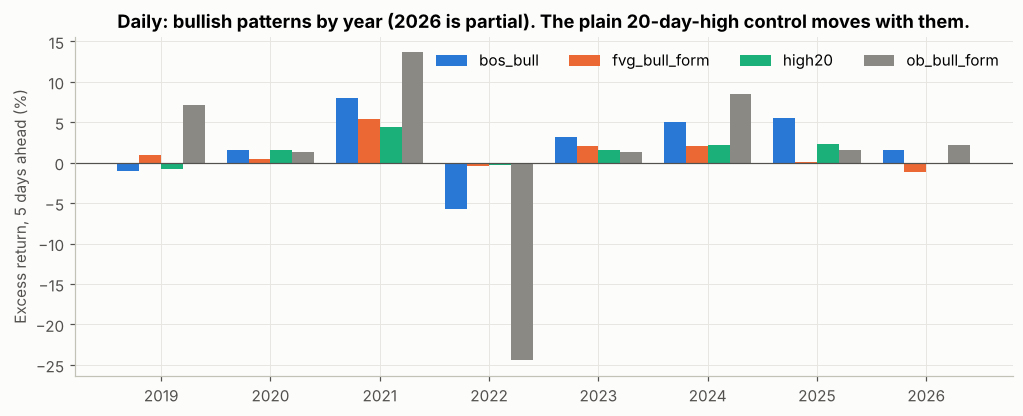

year,2019,2020,2021,2022,2023,2024,2025,2026
pattern,,,,,,,,
bos_bull,-1.01,1.54,8.02,-5.68,3.24,5.00,5.59,1.56
fvg_bull_form,0.97,0.47,5.40,-0.39,2.02,2.08,0.14,-1.17
high20,-0.74,1.55,4.39,-0.33,1.56,2.22,2.32,-0.09
ob_bull_form,7.14,1.31,13.64,-24.45,1.31,8.45,1.57,2.21


In [10]:
def by_year(coins, tf, pats):
    rows = []
    h = H[tf]
    for pat, d in pats:
        for yr in range(2019, 2027):
            ex = []
            for s, c in coins.items():
                idx = c['events'].loc[c['events']['pattern'] == pat, 'i'].to_numpy()
                r = c['fwd'][h]; ok = np.asarray(c['ohlc'].index.year == yr) & ~np.isnan(r)
                sel = idx[ok[idx]] if ok.sum() >= 20 else []
                if len(sel):
                    ex.append((d * (r[sel].mean() - r[ok].mean()), len(sel)))
            if ex:
                n = sum(k for _, k in ex)
                rows.append((pat, yr, 100 * sum(e * k for e, k in ex) / n))
    return pd.DataFrame(rows, columns=['pattern', 'year', 'excess']).pivot(index='pattern', columns='year', values='excess')

yd = by_year(mom['daily'], 'daily', [('bos_bull', 1), ('ob_bull_form', 1), ('fvg_bull_form', 1), ('high20', 1)])
fig, ax = plt.subplots(figsize=(11, 4))
w = 0.2
for k, (pat, c) in enumerate(zip(yd.index, [BLUE, ORANGE, AQUA, '#8a8984'])):
    ax.bar(np.arange(len(yd.columns)) + (k - 1.5) * w, yd.loc[pat], w, color=c, label=pat)
ax.axhline(0, color='#52514e', lw=0.8)
ax.set_xticks(range(len(yd.columns))); ax.set_xticklabels(yd.columns)
ax.set_ylabel('Excess return, 5 days ahead (%)'); ax.set_title('Daily: bullish patterns by year (2026 is partial). The plain 20-day-high control moves with them.')
ax.legend(frameon=False, ncol=4)
plt.show()
yd.round(2)

## 4. Strict trade test (daily and 4-hour)

The same protocol as `proof_analysis.ipynb`: entry at the next bar's open, 0.15% cost per side, **filter (none / above 50-bar average / above 200-bar average) and exit rules chosen on pre-2024 trades only**, then run unchanged since 2024 and compared with **random entries obeying the same filter and exit rules**.
**Proven** = ≥30 trades, q < 0.10 over all strategies below, positive average from 2025 on, and positive on ≥4 of 6 coins. The plain new-high strategy (`high20` / `high60`) is included as the benchmark.
Hourly bars are not simulated: the best hourly excess in section 2 is about 0.26% over 24 hours, below the 0.30% round-trip cost.

In [11]:
FILT = ('none', 'with_sma50', 'with_sma200')
cands = {'daily': (GRID_DAILY, 20, [('bos_bull', 1), ('ob_bull_form', 1), ('fvg_bull_form', 1), ('ob_bull_retest', 1), ('fvg_bear_retest', -1), ('high20', 1)]),
         '4h': (GRID_4H, 60, [('bos_bull', 1), ('ob_bull_form', 1), ('fvg_bull_form', 1), ('fvg_bear_retest', -1), ('high60', 1)])}
rows, recs = [], {}
for tf, (grid, n, pats) in cands.items():
    c = mom[tf]; add_features(c, tf_secs=86400 if tf == 'daily' else 14400)
    for pat, d in pats:
        out = evaluate(c, pat, d, TEST_START, grid, filters=FILT, n_perm=300)
        if out:
            r, rec = out; r['tf'] = tf; rows.append(r); recs[(tf, pat)] = rec
trade = judge(pd.DataFrame(rows)).sort_values('q_value')
print(len(trade), 'strategies;', int(trade['proven'].sum()), 'proven')
trade[['tf', 'pattern', 'side', 'filter', 'rules', 'is_avg_net_pct', 'n', 'win_rate', 'avg_net_pct', 'random_avg_pct', 'profit_factor',
       'p_value', 'q_value', 'avg_net_2025_pct', 'n_2025', 'coins_pos', 'proven']].reset_index(drop=True).round(2)

11 strategies; 0 proven


,tf,pattern,side,filter,rules,is_avg_net_pct,n,win_rate,avg_net_pct,random_avg_pct,profit_factor,p_value,q_value,avg_net_2025_pct,n_2025,coins_pos,proven
0,daily,bos_bull,long,with_sma200,stop - / tgt - / 20 bars,13.60,34,0.53,8.45,-0.16,2.75,0.01,0.11,2.13,15,6,False
1,daily,ob_bull_retest,long,with_sma50,stop 2.0 / tgt - / 20 bars,5.23,19,0.53,8.26,0.33,2.72,0.03,0.15,-1.72,10,6,False
2,daily,ob_bull_form,long,with_sma200,stop - / tgt - / 20 bars,16.35,27,0.48,6.47,0.38,1.74,0.07,0.26,-8.84,14,6,False
3,daily,fvg_bear_retest,short,none,stop 2.0 / tgt - / 20 bars,1.45,146,0.52,2.05,0.66,1.45,0.10,0.26,3.55,94,5,False
4,daily,fvg_bull_form,long,with_sma200,stop - / tgt - / 20 bars,8.69,85,0.41,2.36,-0.08,1.34,0.13,0.27,-2.19,47,6,False
5,daily,high20,long,with_sma200,stop - / tgt - / 20 bars,9.27,90,0.43,2.12,-0.06,1.29,0.15,0.27,-3.98,48,4,False
6,4h,fvg_bear_retest,short,with_sma200,stop 2.0 / tgt - / 60 bars,0.96,372,0.31,0.28,-0.13,1.09,0.17,0.27,0.92,254,3,False
7,4h,bos_bull,long,with_sma200,stop - / tgt - / 60 bars,3.03,180,0.45,1.24,0.66,1.31,0.30,0.41,-1.28,109,5,False
8,4h,ob_bull_form,long,with_sma200,stop - / tgt - / 60 bars,4.67,129,0.47,1.26,0.75,1.31,0.36,0.43,0.39,80,6,False
9,4h,fvg_bull_form,long,with_sma200,stop - / tgt - / 60 bars,3.06,291,0.47,0.32,0.68,1.06,0.71,0.76,-0.80,176,4,False


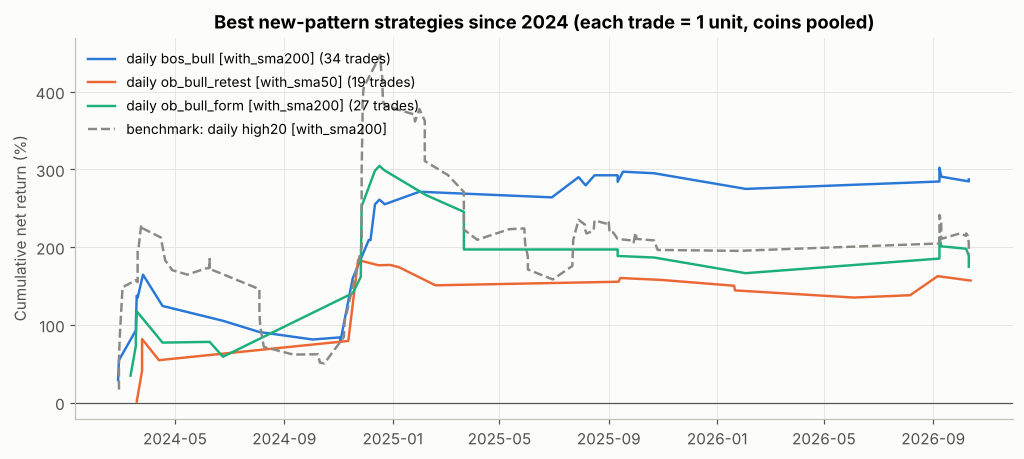

Closest: daily bos_bull [with_sma200]  average net by year (%) and by coin (%)


entry,2024,2025,2026
avg net %,13.4,4.4,-1.3
trades,19.0,9.0,6.0


coin,ADA,BNB,DOGE,ETH,SOL,XRP
avg net %,5.4,1.4,26.6,6.9,7.3,17.6


In [12]:
top = trade.head(3)
fig, ax = plt.subplots()
for (_, r), c in zip(top.iterrows(), [BLUE, ORANGE, AQUA]):
    t = recs[(r['tf'], r['pattern'])].sort_values('exit')
    ax.plot(t['exit'], 100 * t['net'].cumsum(), color=c, label=f"{r['tf']} {r['pattern']} [{r['filter']}] ({len(t)} trades)")
b = trade[trade['pattern'].str.startswith('high')].iloc[0]
t = recs[(b['tf'], b['pattern'])].sort_values('exit')
ax.plot(t['exit'], 100 * t['net'].cumsum(), color='#8a8984', ls='--', label=f"benchmark: {b['tf']} {b['pattern']} [{b['filter']}]")
ax.axhline(0, color='#52514e', lw=0.8); ax.set_ylabel('Cumulative net return (%)')
ax.set_title('Best new-pattern strategies since 2024 (each trade = 1 unit, coins pooled)'); ax.legend(frameon=False, fontsize=9, loc='upper left')
plt.show()
r0 = top.iloc[0]; t = recs[(r0['tf'], r0['pattern'])]
print(f"Closest: {r0['tf']} {r0['pattern']} [{r0['filter']}]  average net by year (%) and by coin (%)")
g = t.groupby(t['entry'].dt.year)['net']
display(pd.DataFrame({'avg net %': 100 * g.mean(), 'trades': g.size()}).round(1).T)
display((100 * t.groupby(t['coin'].str[:-4])['net'].mean()).round(1).to_frame('avg net %').T)

## 5. Cup and handle: too rare to test

The detector is verified (section 1), but real cups are rare: about 0.3-0.9 per 1,000 bars. Classic outcome statistics, using the pattern's own measured move: **target** = right rim + cup depth, **stop** = lowest close of the handle, whichever the highs/lows touch first within one cup-width after the breakout.

In [13]:
rows = []
for tf in ('daily', '4h', 'hourly'):
    for s, c in data[tf].items():
        o = c['ohlc']; cl = np.log(o['close'].to_numpy()); hi = np.log(o['high'].to_numpy()); lo = np.log(o['low'].to_numpy())
        for p in find_cup_handles(cl, **CUP_PARAMS[tf]):
            res = 'timeout'
            for j in range(p.break_i + 1, min(p.break_i + p.width, len(cl) - 1) + 1):
                if lo[j] <= p.stop:
                    res = 'stop'; break
                if hi[j] >= p.target:
                    res = 'target'; break
            fwd = cl[min(p.break_i + p.width // 3, len(cl) - 1)] - cl[p.break_i]
            rows.append(dict(tf=tf, coin=s[:-4], breakout=o.index[p.break_i].date(), outcome=res, ret_after_third_of_width_pct=100 * fwd,
                             recent=o.index[p.break_i] >= pd.Timestamp(TEST_START)))
cups = pd.DataFrame(rows)
print(cups.groupby('tf')['outcome'].value_counts().unstack(fill_value=0).to_string())
print(f"\nAll {len(cups)} detections: target first {100 * (cups['outcome'] == 'target').mean():.0f}%, stop first {100 * (cups['outcome'] == 'stop').mean():.0f}%, "
      f"neither {100 * (cups['outcome'] == 'timeout').mean():.0f}%;  mean return after one third of the cup width: {cups['ret_after_third_of_width_pct'].mean():.1f}%")
cups.sort_values('breakout').tail(8)

outcome  stop  target  timeout
tf                            
4h          7       9        1
daily       4       2        1
hourly     21      10        3

All 58 detections: target first 36%, stop first 55%, neither 9%;  mean return after one third of the cup width: 4.6%


,tf,coin,breakout,outcome,ret_after_third_of_width_pct,recent
12,4h,SOL,2026-01-12,stop,-11.056556,True
31,hourly,ETH,2026-01-13,stop,-12.203342,True
37,hourly,BNB,2026-01-13,stop,-3.162703,True
32,hourly,ETH,2026-04-17,stop,-4.905302,True
44,hourly,XRP,2026-04-21,stop,-5.014939,True
57,hourly,DOGE,2026-05-04,stop,-6.640643,True
3,daily,BNB,2026-09-03,timeout,5.764014,True
0,daily,ETH,2026-09-06,stop,-2.713377,True


## Are the detectors accurate? Yes, with one caveat on cups

- **24 of 24 automated tests pass.** Every SMC definition is checked on hand-built candles with known answers, including near-misses that must *not* fire (a wick through a level is not a BOS, a close below a level is not a sweep, overlapping candles are not a gap).
- **No lookahead.** Re-running every detector on truncated data gives identical events, on both random and real prices.
- **Cup and handle:** a planted cup was found at the right place (left rim bar 29 vs 30, right rim 90 vs 90), and all 6 malformed variants (V-shape, deep handle, too narrow, too shallow, uneven rims, short handle) were rejected. My first version was too loose; I tightened the shape rules by looking at charts, not returns.
- **Visual check:** the annotated charts match the written definitions, and the daily cups (ADA, XRP, DOGE, SOL in late 2023) look like textbook cups.
- **Caveat:** on daily bars cups occur about **2.4× more often than in shuffled prices** (0.40 vs 0.17 per 1,000 bars), but on 4-hour bars **no more often than chance** (0.16 vs 0.14), so many 4-hour "cups" are noise-level.
- **Not verifiable:** whether my definitions match any particular trader's. SMC terms (order block, CHoCH) are used loosely and other rule sets differ in the details.

## Do the patterns predict? Mostly momentum, and nothing is proven

- **8 of 45 pattern-and-timeframe combinations pass the correction for testing many patterns**, and they are almost all *bullish* ones: daily bullish order-block formation (+4.6% over random entries since 2024), bullish BOS (+4.1%), bullish order-block retest (+4.2%, only 35 events), daily bearish-FVG retest (+1.4%), and 4-hour and hourly bullish BOS and FVG formation (+0.1% to +0.8%).
- **Most of that is plain momentum.** A new 20-day closing high with no smart-money logic gives +1.8% since 2024 (+2.6% before). Daily bullish BOS beats it (+4.1% and +4.0%), but on 4-hour bars they are equal (+0.8% vs +1.1%). So BOS adds little or nothing beyond "price made a new high".
- **It only works in bull markets.** Bullish BOS was positive in 2020, 2021 and 2023-2026 but **−5.7% in 2022** and −1.0% in 2019.
- **The distinctly smart-money signals show no consistent edge:** liquidity sweeps (both directions, all timeframes), CHoCH, and most gap and block retests.
- **Hourly effects are too small to trade:** the best is about +0.26% over 24 hours, below the 0.30% round-trip cost.

## Trading them: 0 of 11 strategies proven

- With the filter and exit rules chosen only on pre-2024 trades, none passed. The closest is **daily bullish BOS, bought only above the 200-day average, held 20 days: +8.5% per trade since 2024** (random entries −0.2%, 34 trades, positive on all 6 coins, q = 0.11, just missing the 0.10 bar). But it is fading: **+13.4% in 2024 (19 trades), +4.4% in 2025 (9), −1.3% in 2026 (6)**.
- **Daily bearish-FVG retest as a short** (146 trades, +2.1% per trade, +3.6% since 2025, 5 of 6 coins) is the steadier near-miss, but q = 0.26.
- The plain new-high momentum benchmark also fails (q = 0.27), consistent with the "mostly momentum" reading.

## Cup and handle: accurate to detect, too rare to test

- 58 detections across all timeframes (7 on daily bars). Using the pattern's own measured move, **price hit the target before the stop only 36% of the time and the stop first 55%**, nowhere near the 95% some websites claim. With samples this small, treat it as unproven, not disproven.

## Bottom line

The new detectors are correct, but **the popular patterns do not give an edge you can trade beyond momentum.** The best earlier lead, **shorting after a daily MACD bearish divergence** (the strategy in `paper_strategies.json`), remains the only strategy that passed the strict test. If you want to follow up here, the daily bearish-FVG retest short is the one worth adding to the paper-trading log.